# **Phase 8: Data Visualization**

**Project**

Meridian Retail Group: Diagnosing and Predicting Customer Churn

**Objective**

The objective of this phase is to communicate the findings from the exploratory data analysis using clear, informative visualizations.

**Requirements**

* Create at least four visualizations using Matplotlib.
* Create at least two interactive visualizations using Plotly.
* Give every chart an appropriate title and labelled axes.
* Add a short caption explaining the insight supported by each chart.

The visualizations will focus on customer churn, customer segments, purchasing behaviour, and support-ticket patterns.

In [ ]:
# Phase 8: Data Visualization
# Step 1: Connect Google Drive and load the cleaned datasets
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
# Folder containing the cleaned datasets from Phase 6
data_folder = "/content/drive/MyDrive/Meridian_Phase6_Cleaned_Data"
# Load the cleaned datasets
customers = pd.read_csv(f"{data_folder}/customers_clean.csv")
orders = pd.read_csv(f"{data_folder}/orders_clean.csv")
order_items = pd.read_csv(f"{data_folder}/order_items_clean.csv")
products = pd.read_csv(f"{data_folder}/products_clean.csv")
support_tickets = pd.read_csv(f"{data_folder}/support_tickets_clean.csv")
# Display the number of rows and columns in each dataset
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Support Tickets:", support_tickets.shape)

Mounted at /content/drive
Customers: (6002, 19)
Orders: (28272, 9)
Order Items: (73465, 5)
Products: (220, 9)
Support Tickets: (5200, 8)


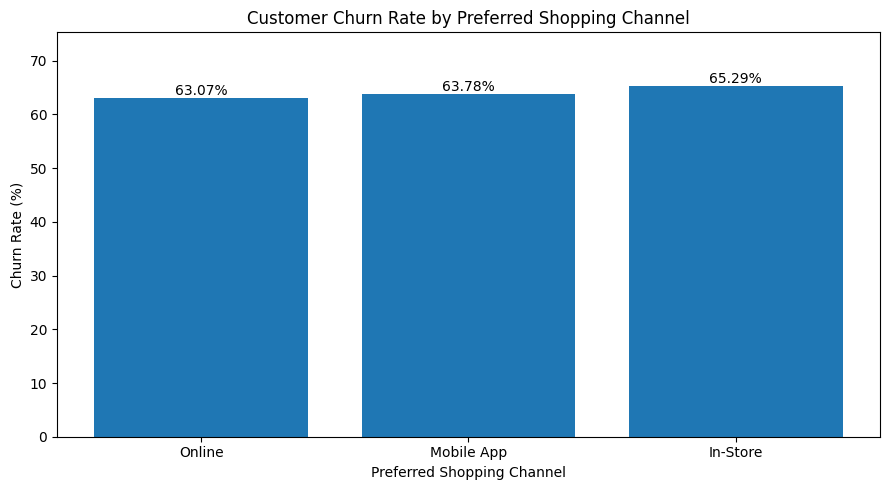

,total_customers,churned_customers,churn_rate_pct
preferred_channel,,,
Online,1825,1151,63.068493
Mobile App,1883,1201,63.7812
In-Store,1858,1213,65.285253


In [ ]:
# Phase 8: Chart 1
# Customer Churn Rate by Preferred Shopping Channel
# Convert signup dates to datetime
customers["signup_date"] = pd.to_datetime(
    customers["signup_date"], errors="coerce"
)
# Convert order dates to datetime
orders["order_date"] = pd.to_datetime(
    orders["order_date"], errors="coerce"
)
# Standardise order status
orders["order_status"] = (
    orders["order_status"].astype("string").str.strip().str.title()
)
# Define the reference date and churn threshold used in Phase 7
reference_date = pd.Timestamp("2026-07-01")
churn_threshold = 180
# Select completed orders with valid dates on or before the reference date
completed_orders = orders[
    (orders["order_status"] == "Completed") &
    (orders["order_date"].notna()) &
    (orders["order_date"] <= reference_date)
].copy()
# Find each customer's most recent completed order
last_order = completed_orders.groupby("customer_id")["order_date"].max()
# Calculate recency in days
rfm_recency = (
    reference_date - last_order
).dt.days.rename("recency_days")
# Attach recency to the customer dataset
chart_data = customers.merge(
    rfm_recency, on="customer_id", how="left"
)
# Classify churn, leaving customers without valid recency unclassified
chart_data["churn_status"] = pd.NA
chart_data.loc[
    chart_data["recency_days"] > churn_threshold, "churn_status"
] = 1
chart_data.loc[
    chart_data["recency_days"] <= churn_threshold, "churn_status"
] = 0
# Calculate churn rate for each preferred shopping channel
channel_summary = (
    chart_data.dropna(subset=["churn_status", "preferred_channel"])
    .groupby("preferred_channel")
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churn_status", "sum")
    )
)
channel_summary["churn_rate_pct"] = (
    channel_summary["churned_customers"] /
    channel_summary["total_customers"] * 100
)
# Create the Matplotlib bar chart
channel_summary = channel_summary.sort_values("churn_rate_pct")
plt.figure(figsize=(9, 5))
bars = plt.bar(
    channel_summary.index,
    channel_summary["churn_rate_pct"]
)
plt.title("Customer Churn Rate by Preferred Shopping Channel")
plt.xlabel("Preferred Shopping Channel")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, channel_summary["churn_rate_pct"].max() + 10)
# Display the percentage above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )
plt.tight_layout()
plt.show()
# Display the values used in the chart
display(channel_summary.round(2))

Interpretation: In-Store customers had the highest churn rate (65.29%), while Online customers had the lowest (63.07%). Although the difference is modest, Meridian could investigate whether customer experiences vary across shopping channels. These results show an association and do not prove that the shopping channel causes churn.

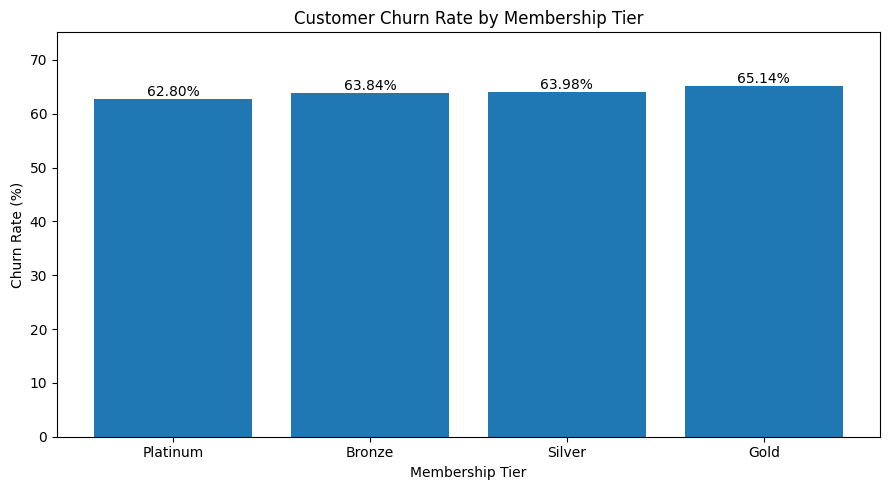

,total_customers,churned_customers,churn_rate_pct
membership_tier,,,
Platinum,371,233,62.803235
Bronze,2558,1633,63.838937
Silver,1613,1032,63.980161
Gold,1024,667,65.136719


In [ ]:
# Phase 8: Chart 2
# Customer Churn Rate by Membership Tier
# Group customers by membership tier and calculate churn
tier_summary = (
    chart_data.dropna(subset=["churn_status", "membership_tier"])
    .groupby("membership_tier")
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churn_status", "sum")
    )
)
# Calculate churn rate as a percentage
tier_summary["churn_rate_pct"] = (
    tier_summary["churned_customers"] /
    tier_summary["total_customers"] * 100
)
# Arrange tiers by churn rate
tier_summary = tier_summary.sort_values("churn_rate_pct")
# Create the bar chart
plt.figure(figsize=(9, 5))
bars = plt.bar(
    tier_summary.index,
    tier_summary["churn_rate_pct"]
)
plt.title("Customer Churn Rate by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, tier_summary["churn_rate_pct"].max() + 10)
# Display the churn percentage above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )
plt.tight_layout()
plt.show()
# Display the results
display(tier_summary.round(2))

Interpretation: Gold customers recorded the highest churn rate at approximately 65.14%, while Platinum customers recorded the lowest at approximately 62.80%. The difference is relatively small, so Meridian should investigate other factors before deciding whether membership tier is an important driver of churn.

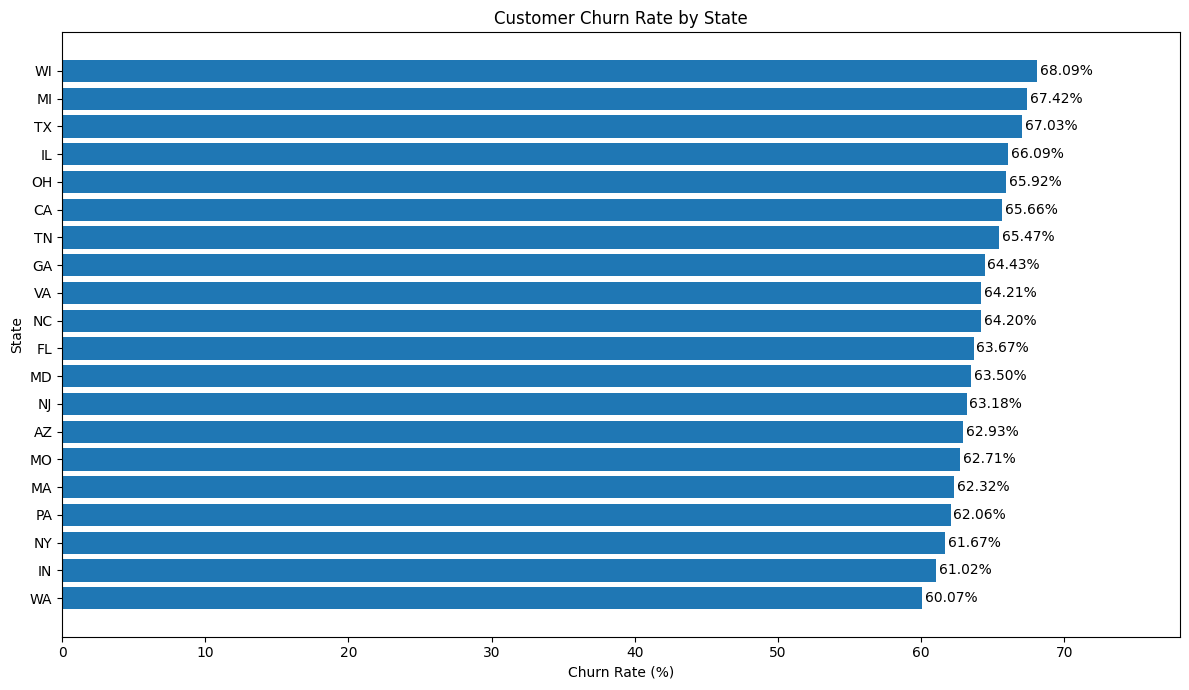

,total_customers,churned_customers,churn_rate_pct
state,,,
WA,278,167,60.071942
IN,236,144,61.016949
NY,300,185,61.666667
PA,282,175,62.056738
MA,284,177,62.323944
MO,295,185,62.711864
AZ,294,185,62.92517
NJ,258,163,63.178295
MD,263,167,63.498099


In [ ]:
# Phase 8: Chart 3
# Customer Churn Rate by State
# Group customers by state and calculate churn
state_summary = (
    chart_data.dropna(subset=["churn_status", "state"])
    .groupby("state")
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churn_status", "sum")
    )
)
# Calculate churn rate as a percentage
state_summary["churn_rate_pct"] = (
    state_summary["churned_customers"] /
    state_summary["total_customers"] * 100
)
# Sort states from lowest to highest churn rate
state_summary = state_summary.sort_values("churn_rate_pct")
# Create the bar chart
plt.figure(figsize=(12, 7))
bars = plt.barh(
    state_summary.index,
    state_summary["churn_rate_pct"]
)
plt.title("Customer Churn Rate by State")
plt.xlabel("Churn Rate (%)")
plt.ylabel("State")
plt.xlim(0, state_summary["churn_rate_pct"].max() + 10)
# Display churn percentages beside the bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )
plt.tight_layout()
plt.show()
# Display the results
display(state_summary.round(2))

Interpretation: Wisconsin recorded the highest customer churn rate (68.09%), while Washington recorded the lowest (60.07%), an 8.01-percentage-point difference. Meridian should investigate regional differences in customer experience and service delivery to understand this variation. The chart identifies a pattern but does not establish its cause.

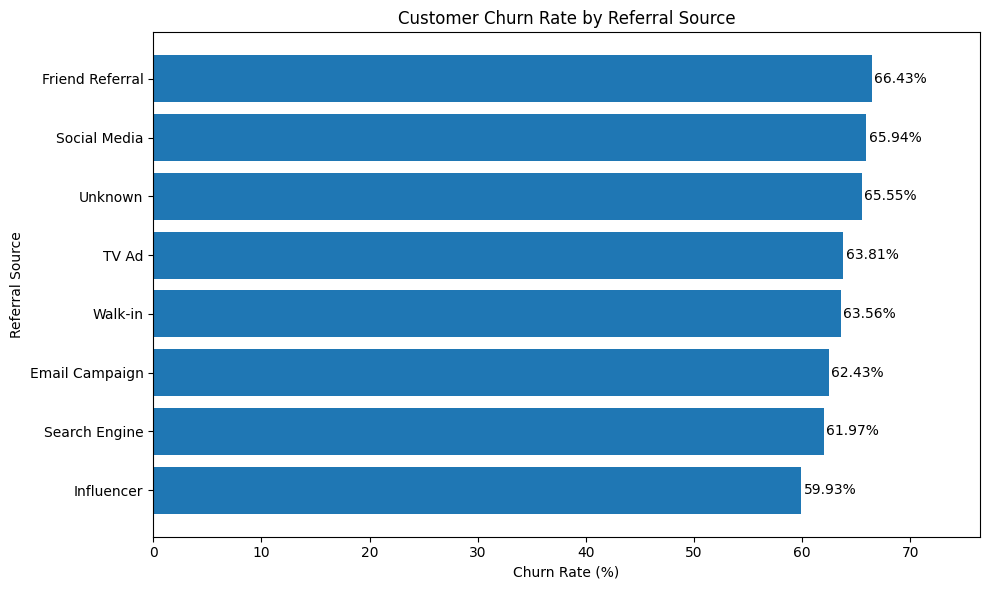

,total_customers,churned_customers,churn_rate_pct
referral_source_group,,,
Influencer,574,344,59.930314
Search Engine,547,339,61.974406
Email Campaign,551,344,62.431942
Walk-in,601,382,63.560732
TV Ad,572,365,63.811189
Unknown,1559,1022,65.554843
Social Media,593,391,65.935919
Friend Referral,569,378,66.432337


In [ ]:
# Phase 8: Chart 4
# Customer Churn Rate by Referral Source
# Create a referral-source category for missing values
chart_data["referral_source_group"] = (
    chart_data["referral_source"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)
# Calculate churn rates by referral source
referral_summary = (
    chart_data.dropna(subset=["churn_status"])
    .groupby("referral_source_group")
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churn_status", "sum")
    )
)
# Calculate churn rate as a percentage
referral_summary["churn_rate_pct"] = (
    referral_summary["churned_customers"] /
    referral_summary["total_customers"] * 100
)
# Sort from lowest to highest churn rate
referral_summary = referral_summary.sort_values("churn_rate_pct")
# Create the horizontal bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(
    referral_summary.index,
    referral_summary["churn_rate_pct"]
)
plt.title("Customer Churn Rate by Referral Source")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Referral Source")
plt.xlim(0, referral_summary["churn_rate_pct"].max() + 10)
# Add percentage labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )
plt.tight_layout()
plt.show()
# Display the results
display(referral_summary.round(2))

Interpretation: Customers acquired through Friend Referral had the highest churn rate (66.43%), while those acquired through Influencer referrals had the lowest (59.93%). In addition, 1,559 customers had unknown referral sources, making accurate acquisition tracking an important improvement area for Meridian. These results show associations and do not prove that a referral source causes churn.

In [ ]:
# Phase 8: Chart 5
# Interactive Plotly Chart: Churn Rate by Membership Tier
fig = px.bar(
    tier_summary.reset_index(),
    x="membership_tier",
    y="churn_rate_pct",
    hover_data=[
        "total_customers",
        "churned_customers"
    ],
    title="Interactive Customer Churn Rate by Membership Tier",
    labels={
        "membership_tier": "Membership Tier",
        "churn_rate_pct": "Churn Rate (%)",
        "total_customers": "Total Customers",
        "churned_customers": "Churned Customers"
    },
    text="churn_rate_pct"
)
fig.update_traces(texttemplate="%{text:.2f}%", textposition="outside")
fig.update_layout(
    xaxis_title="Membership Tier",
    yaxis_title="Churn Rate (%)",
    yaxis_range=[0, 80]
)
fig.show()

Interpretation: This interactive chart compares churn rates across the four membership tiers. Gold customers have the highest churn rate (65.14%), while Platinum customers have the lowest (62.80%). Hovering over each bar reveals the total number of customers and the number who churned, allowing Meridian to explore the differences between tiers.

In [ ]:
# Phase 8: Chart 6
# Interactive Plotly Chart: Churn Rate by Referral Source
fig = px.bar(
    referral_summary.reset_index(),
    x="referral_source_group",
    y="churn_rate_pct",
    hover_data=[
        "total_customers",
        "churned_customers"
    ],
    title="Interactive Customer Churn Rate by Referral Source",
    labels={
        "referral_source_group": "Referral Source",
        "churn_rate_pct": "Churn Rate (%)",
        "total_customers": "Total Customers",
        "churned_customers": "Churned Customers"
    },
    text="churn_rate_pct"
)
fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)
fig.update_layout(
    xaxis_title="Referral Source",
    yaxis_title="Churn Rate (%)",
    yaxis_range=[0, 80],
    xaxis_tickangle=-30
)
fig.show()

Interpretation: Customers acquired through Friend Referral had the highest churn rate (66.43%), while those acquired through Influencer referrals had the lowest (59.93%). The chart also reveals that 1,559 customers had unknown referral sources, highlighting the need for Meridian to improve its acquisition-data tracking.

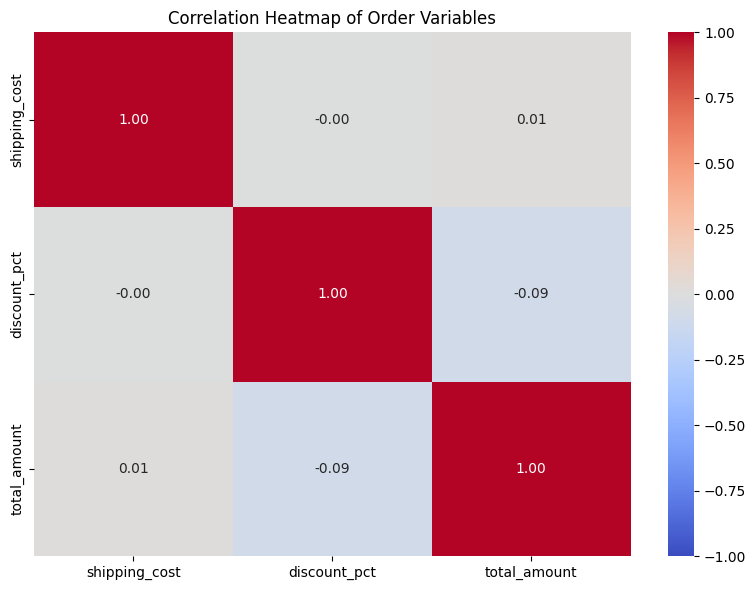

In [ ]:
# Phase 8: Chart 7
# Matplotlib Correlation Heatmap

import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns from the orders dataset
numeric_orders = orders[
    ["shipping_cost", "discount_pct", "total_amount"]
].copy()

# Convert selected columns to numeric values
for column in numeric_orders.columns:
    numeric_orders[column] = pd.to_numeric(
        numeric_orders[column], errors="coerce"
    )

# Calculate correlations
correlation_matrix = numeric_orders.corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Order Variables")
plt.tight_layout()
plt.show()

Interpretation: The correlation heatmap shows the strength and direction of the relationships between shipping cost, discount percentage, and total order amount. These relationships can help Meridian understand patterns in its order data; however, correlation does not imply causation.

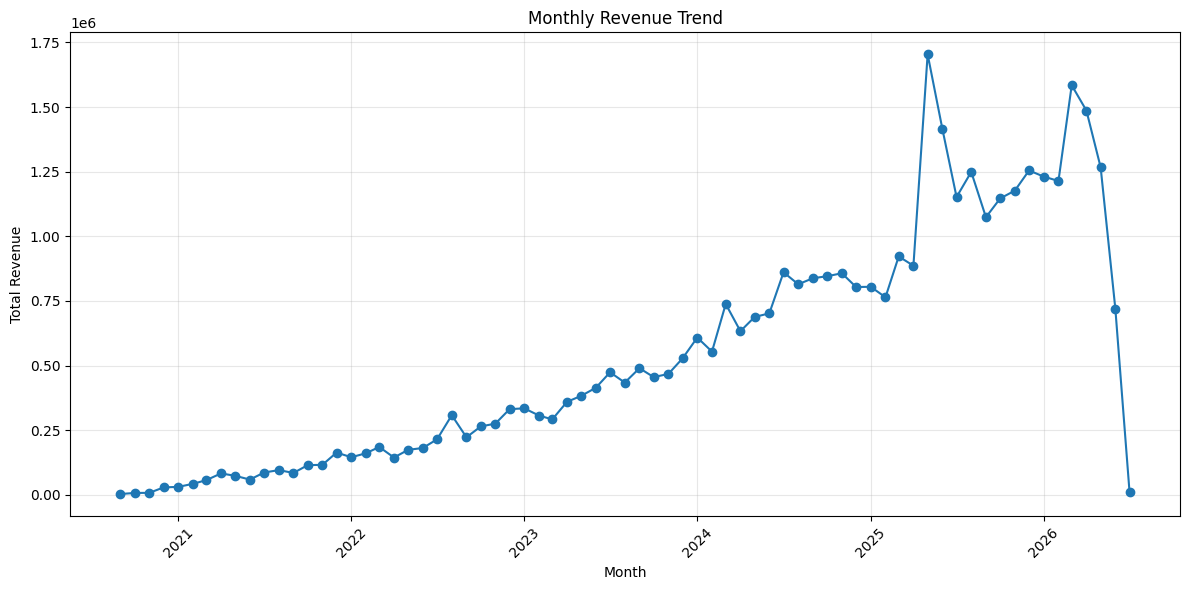

In [ ]:
# Phase 8: Chart 8
# Matplotlib: Monthly Revenue Trend

# Make sure order_date is in datetime format
orders["order_date"] = pd.to_datetime(
    orders["order_date"], errors="coerce"
)

# Keep completed orders up to the project reference date
reference_date = pd.Timestamp("2026-07-01")

completed_orders = orders[
    (orders["order_status"].str.strip().str.lower() == "completed") &
    (orders["order_date"].notna()) &
    (orders["order_date"] <= reference_date)
].copy()

# Calculate monthly revenue
completed_orders["month"] = (
    completed_orders["order_date"].dt.to_period("M")
)

monthly_revenue = (
    completed_orders.groupby("month")["total_amount"]
    .sum()
    .reset_index()
)

# Convert month values to dates for plotting
monthly_revenue["month"] = (
    monthly_revenue["month"].dt.to_timestamp()
)

# Plot the revenue trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["total_amount"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation: The monthly revenue trend illustrates how revenue from completed orders changes over time. Peaks and declines can help Meridian identify periods of stronger or weaker sales and guide further investigation into seasonal patterns and customer purchasing behaviour.

**Phase** **8**: **Data** **Visualization** — **Final** **Summary**

Overview

In this phase, data visualization techniques were used to explore customer churn, customer segments, order variables, and revenue trends at Meridian Retail Group. Eight visualizations were developed using Matplotlib and Plotly to communicate the findings clearly.

Visualizations Completed

Four Matplotlib charts examined customer churn by preferred shopping channel, membership tier, state, and referral source. An additional Matplotlib correlation heatmap explored relationships between numerical order variables, while a monthly revenue trend illustrated how revenue from completed orders changed over time.

Two interactive Plotly charts were also created to explore customer churn by membership tier and referral source. These charts allow users to inspect additional customer counts by hovering over the bars.

Key Findings

* In-store customers had the highest churn rate among the three shopping channels, at approximately 65.29%, while online customers had the lowest, at approximately 63.07%.
* Gold-tier customers had the highest churn rate, at approximately 65.14%, while Platinum-tier customers had the lowest, at approximately 62.80%.
* Wisconsin recorded the highest state-level churn rate, at approximately 68.09%, while Washington recorded the lowest, at approximately 60.07%.
* Customers acquired through friend referrals had the highest churn rate, at approximately 66.43%, while customers acquired through influencer referrals had the lowest, at approximately 59.93%.
* The correlation heatmap and monthly revenue trend provide additional information about order-variable relationships and revenue patterns that can support further investigation.

Conclusion

The visualizations highlight differences in churn across customer groups and provide a clearer understanding of Meridian’s customer-retention challenges. These findings can help guide further investigation and inform retention strategies. However, observed relationships do not necessarily establish causation, and the findings should be considered alongside the limitations of the available data.

The insights from this phase provide a foundation for Phase 9, where machine learning models will be developed and evaluated to predict customer churn.